# Diagnóstico — Onde o modelo final erra?

O modelo final (boosting com onze atributos + idade no lançamento, notebook 11) tem RMSE OOF repetido de **0,5195**. Esse número é uma média sobre os 4000 pares. Um bom desempenho médio pode esconder grupos em que o modelo erra muito mais, ou erra sempre para o mesmo lado.

**Perguntas**
1. O erro é muito diferente entre regiões dos dados (número de avaliações, gênero, idade, ano, afinidade, idade no lançamento)?
2. Há **viés sistemático**: faixas em que o modelo erra sempre para o mesmo lado?
3. Como o modelo se comporta nas **notas extremas** (0 e 5 estrelas)?

Este notebook não ajusta modelos novos nem altera o modelo final.

### O que este notebook traz de novo

| | |
|---|---|
| **Ponto de partida** | O modelo final, avaliado só pelo RMSE agregado. |
| **O que muda** | Separamos os erros por região dos dados, em duas medidas complementares. |
| **RMSE por subgrupo** | Mede o **tamanho** do erro em cada grupo: para quem o modelo funciona pior? |
| **Resíduo médio** | O resíduo é $y - \hat y$, com sinal. Sua média mede a **direção** do erro: se é positiva numa faixa, o modelo subestima aquele grupo de forma sistemática. |
| **Por que as duas** | Um grupo pode ter resíduo médio zero e RMSE alto (imprecisão: erra muito, para os dois lados) ou RMSE moderado e resíduo médio diferente de zero (viés: erra sempre para o mesmo lado). |
| **Relação com os experimentos anteriores** | É a mesma ferramenta que guiou o projeto: os resíduos motivaram afinidade, curvatura, gênero, idade, ano e nostalgia. Aqui ela é aplicada ao modelo final. |

**Protocolo:** 5 dobras × 5 repetições, semente 2026; as mesmas partições dos experimentos anteriores, apenas `train.csv`, previsões cortadas em [0, 5]. As previsões OOF do modelo final são recalculadas com a mesma busca interna de 3 dobras (`src/final_diagnostics.py`).

Cada linha tem cinco previsões OOF, uma por repetição. O RMSE de cada grupo usa todas elas. Os resíduos dos gráficos usam a média das cinco previsões de cada linha. Os intervalos de 95% do RMSE vêm de reamostragem (bootstrap) das linhas do grupo e servem para saber se a diferença entre grupos é maior que o acaso. As faixas foram definidas antes de olhar os resíduos e são usadas apenas para descrição.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import RepeatedKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.final_diagnostics import MODEL_NAME, final_model_oof
from src.final_submission import add_features, clipped_rmse

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
# O BLAS do macOS emite avisos espúrios de overflow no produto matricial; os resultados não são afetados.
warnings.filterwarnings('ignore', category=RuntimeWarning)

df = add_features(pd.read_csv(ROOT / 'data' / 'train.csv'))
y = df['stars'].to_numpy(dtype=float)
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))

# Busca interna em cada uma das 25 partições: demora alguns minutos.
predictions, by_fold = final_model_oof(df, y, folds)
print(f'RMSE OOF repetido do modelo final: {clipped_rmse(y, predictions):.6f}')

df['erro_quadratico'] = ((y - predictions) ** 2).mean(axis=0)  # média nas 5 repetições
df['previsao'] = predictions.mean(axis=0)
df['residuo'] = y - df['previsao']

RMSE OOF repetido do modelo final: 0.519532


## 1. O erro muda entre regiões dos dados?

Para cada variável, dividimos os pares em faixas e calculamos, em cada faixa: o número de pares, o RMSE com intervalo de 95%, o resíduo médio e o desvio padrão das notas reais. O desvio padrão mostra quão variáveis são as notas naquele grupo: um grupo com notas mais dispersas tende a ter erro maior mesmo com um bom modelo.

In [2]:
rng = np.random.default_rng(SEED)

def by_group(groups, n_boot=500):
    rows = []
    for name, part in df.groupby(groups, observed=True):
        squared = part['erro_quadratico'].to_numpy()
        boot = [np.sqrt(squared[rng.integers(0, len(squared), len(squared))].mean()) for _ in range(n_boot)]
        rows.append({'faixa': str(name), 'pares': len(part),
                     'RMSE': np.sqrt(squared.mean()),
                     'IC 2,5%': np.percentile(boot, 2.5), 'IC 97,5%': np.percentile(boot, 97.5),
                     'resíduo médio': part['residuo'].mean(),
                     'desvio das notas': part['stars'].std()})
    return pd.DataFrame(rows)

GROUPS = {
    'avaliações do usuário': pd.qcut(df['user_n_ratings'], 4),
    'avaliações do filme': pd.qcut(df['movie_n_ratings'], 4),
    'média do usuário': pd.qcut(df['user_avg_stars'], 4),
    'média do filme': pd.qcut(df['movie_avg_stars'], 4),
    'gênero': df['genre'],
    'idade': pd.cut(df['age'], [15, 25, 35, 45, 55, 80]),
    'ano de lançamento': pd.cut(df['release_year'], [1969, 1985, 1995, 2005, 2015, 2024]),
    'afinidade': pd.qcut(df['affinity'], 4),
    'idade no lançamento': pd.cut(df['age_at_release'], [-70, 0, 10, 20, 30, 90]),
}
tables = {name: by_group(groups) for name, groups in GROUPS.items()}
for name, table in tables.items():
    print(name)
    display(table.round(3))

avaliações do usuário


,faixa,pares,RMSE,"IC 2,5%","IC 97,5%",resíduo médio,desvio das notas
0,"(2.999, 14.0]",1060,0.563,0.537,0.585,0.012,1.196
1,"(14.0, 27.0]",976,0.515,0.493,0.537,-0.001,1.151
2,"(27.0, 60.0]",969,0.475,0.456,0.494,0.002,1.189
3,"(60.0, 1016.0]",995,0.518,0.497,0.540,0.003,1.081


avaliações do filme


,faixa,pares,RMSE,"IC 2,5%","IC 97,5%",resíduo médio,desvio das notas
0,"(4.999, 17.0]",1049,0.553,0.529,0.577,0.012,1.147
1,"(17.0, 34.0]",978,0.513,0.493,0.534,-0.002,1.171
2,"(34.0, 66.0]",976,0.505,0.483,0.526,0.003,1.178
3,"(66.0, 1345.0]",997,0.503,0.482,0.523,0.004,1.169


média do usuário


,faixa,pares,RMSE,"IC 2,5%","IC 97,5%",resíduo médio,desvio das notas
0,"(1.0390000000000001, 2.84]",1008,0.560,0.536,0.586,-0.021,1.117
1,"(2.84, 3.34]",995,0.540,0.515,0.565,-0.008,1.054
2,"(3.34, 3.8]",999,0.488,0.468,0.508,0.012,1.055
3,"(3.8, 5.0]",998,0.486,0.466,0.508,0.034,0.997


... (8 outputs left out)

afinidade


,faixa,pares,RMSE,"IC 2,5%","IC 97,5%",resíduo médio,desvio das notas
0,"(0.037, 0.249]",1005,0.551,0.529,0.572,-0.015,1.121
1,"(0.249, 0.39]",1003,0.541,0.521,0.565,0.004,1.072
2,"(0.39, 0.553]",992,0.520,0.496,0.544,0.000,1.060
3,"(0.553, 0.862]",1000,0.461,0.440,0.485,0.028,0.895


idade no lançamento


,faixa,pares,RMSE,"IC 2,5%","IC 97,5%",resíduo médio,desvio das notas
0,"(-70, 0]",844,0.552,0.528,0.578,-0.031,1.181
1,"(0, 10]",630,0.507,0.478,0.535,0.001,1.129
2,"(10, 20]",791,0.488,0.465,0.512,0.091,1.008
3,"(20, 30]",701,0.519,0.492,0.544,-0.001,1.138
4,"(30, 90]",1034,0.523,0.500,0.545,-0.027,1.169


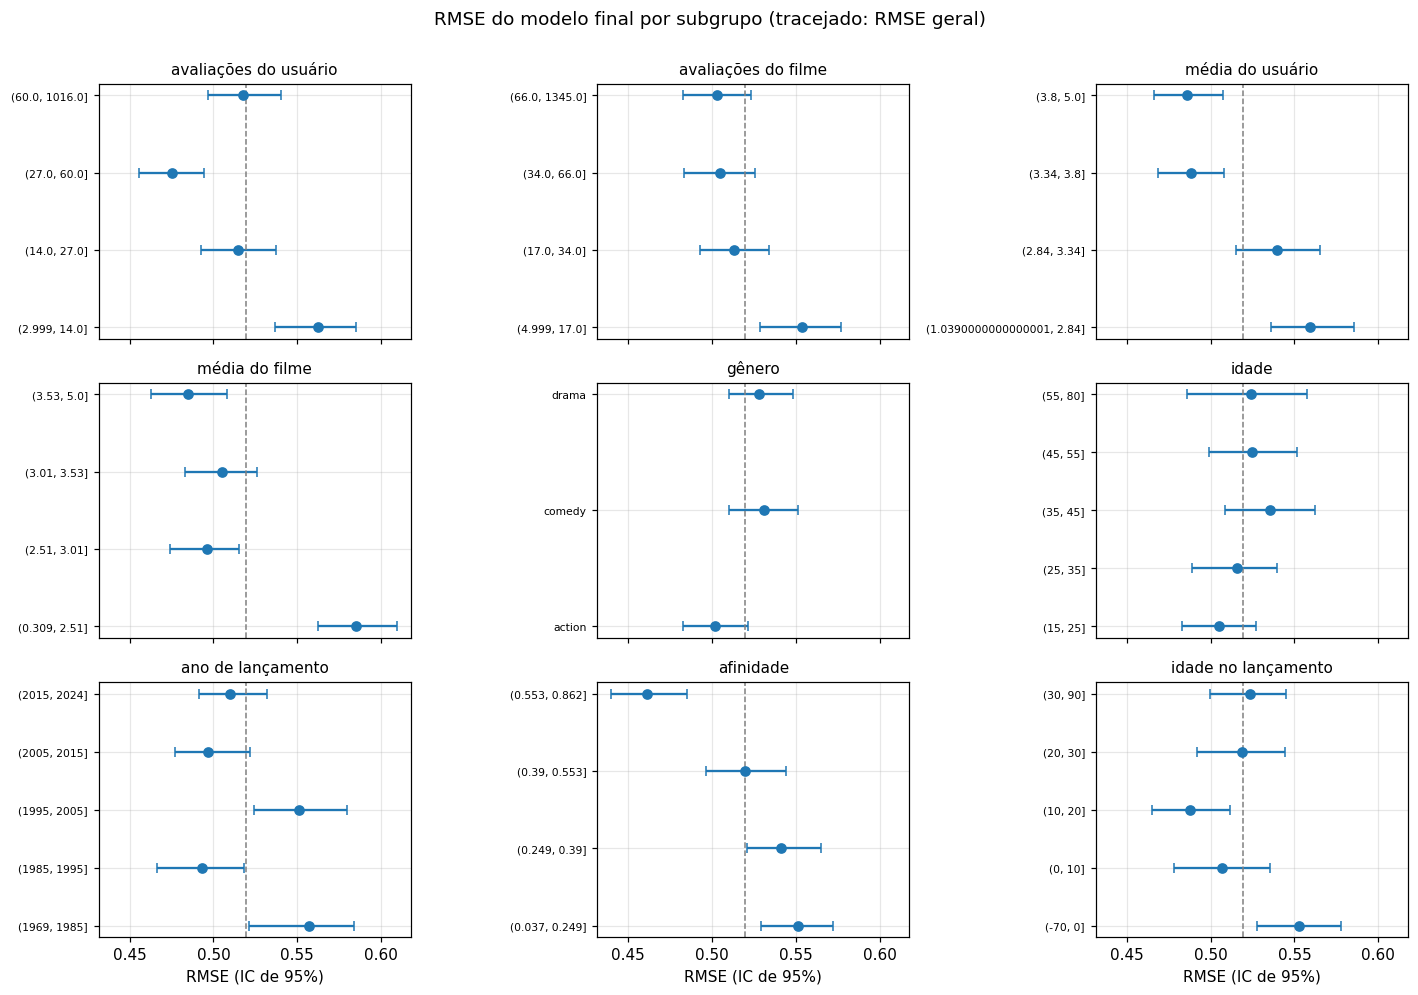

In [3]:
overall = clipped_rmse(y, predictions)
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, (name, table) in zip(axes.ravel(), tables.items()):
    pos = np.arange(len(table))
    ax.errorbar(table['RMSE'], pos,
                xerr=[table['RMSE'] - table['IC 2,5%'], table['IC 97,5%'] - table['RMSE']],
                fmt='o', capsize=3)
    ax.axvline(overall, color='gray', ls='--', lw=1)
    ax.set_yticks(pos)
    ax.set_yticklabels(table['faixa'], fontsize=7)
    ax.set_title(name, fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel('RMSE (IC de 95%)')
fig.suptitle('RMSE do modelo final por subgrupo (tracejado: RMSE geral)', y=1.0)
plt.tight_layout()
plt.show()

**Leitura**
- **O erro varia, mas sem grupos com desempenho muito ruim.** O RMSE vai de cerca de 0,46 a 0,59 nos subgrupos, contra 0,52 no geral. Nenhum grupo se aproxima do erro da regressão de referência (0,82).
- **Pouca informação, mais erro.** Usuários com até 14 avaliações (0,56) e filmes com até 17 avaliações (0,55) erram mais que os grupos com mais avaliações (0,48 a 0,52). Nos usuários, os intervalos do grupo com menos avaliações e do grupo de 27 a 60 avaliações não se sobrepõem: a diferença não é acaso. É o esperado: uma média calculada com poucas notas é uma informação mais ruidosa.
- **Filmes mal avaliados e afinidade baixa são os grupos mais difíceis.** O quartil de menor média do filme tem RMSE 0,59, e o de menor afinidade, 0,55. No outro extremo, o quartil de maior afinidade tem o menor erro (0,46), mas também a menor dispersão das notas (desvio 0,90, contra 1,12 no quartil mais baixo). Parte da diferença de erro vem de os grupos serem intrinsecamente mais ou menos variáveis, e não de o modelo funcionar melhor ou pior.
- **Gênero e idade têm erros parecidos** entre as faixas, com intervalos que se sobrepõem.
- **O resíduo médio é pequeno em quase todas as faixas** (em módulo, até cerca de 0,04 estrela). A exceção é a idade no lançamento entre 10 e 20 anos, analisada na seção 3.

## 2. O modelo erra para um lado conforme o valor que prevê?

Este é o teste de **calibração**: agrupamos os pares pela **previsão** e olhamos o resíduo médio. Num modelo bem calibrado, quando ele prevê 4, a nota real é, em média, 4: o resíduo médio fica perto de zero em todas as faixas de previsão. As barras mostram ±2 erros padrão.

,pares,residuo,abs_residuo
previsao,,,
"(0.0, 1.5]",121,-0.237,0.491
"(1.5, 2.5]",655,-0.021,0.443
"(2.5, 3.0]",532,-0.020,0.437
"(3.0, 3.5]",628,-0.004,0.434
"(3.5, 4.0]",695,-0.008,0.420
"(4.0, 4.5]",650,0.052,0.416
"(4.5, 5.01]",719,0.062,0.253


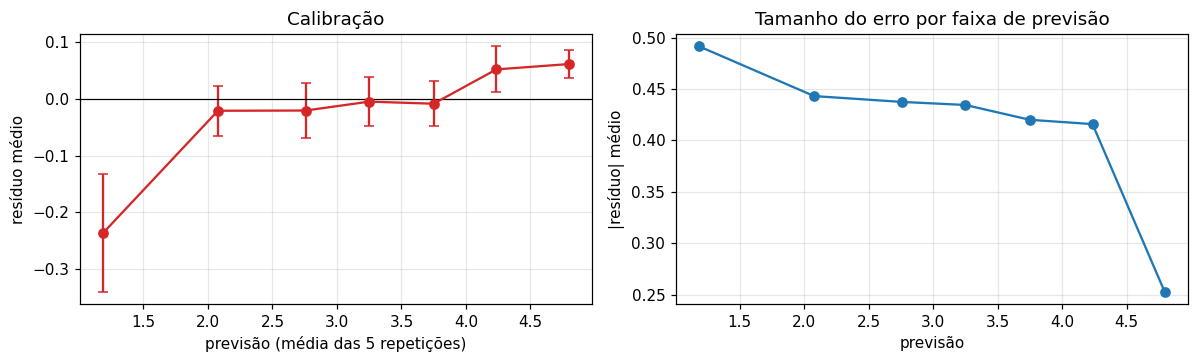

In [4]:
def binned(x, bins):
    groups = pd.cut(x, bins) if not np.isscalar(bins) else pd.qcut(x, bins, duplicates='drop')
    table = df.groupby(groups, observed=True).agg(
        x=(x.name, 'mean'), residuo=('residuo', 'mean'), desvio=('residuo', 'std'),
        abs_residuo=('residuo', lambda s: s.abs().mean()), pares=('residuo', 'size'))
    table['ep'] = table['desvio'] / np.sqrt(table['pares'])
    return table

calib = binned(df['previsao'], [0, 1.5, 2.5, 3, 3.5, 4, 4.5, 5.01])
display(calib[['pares', 'residuo', 'abs_residuo']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].errorbar(calib['x'], calib['residuo'], yerr=2 * calib['ep'], fmt='o-', capsize=3, color='C3')
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set(xlabel='previsão (média das 5 repetições)', ylabel='resíduo médio', title='Calibração')
axes[1].plot(calib['x'], calib['abs_residuo'], 'o-')
axes[1].set(xlabel='previsão', ylabel='|resíduo| médio', title='Tamanho do erro por faixa de previsão')
plt.tight_layout()
plt.show()

**Leitura**
- **Na maior parte da faixa, o modelo está bem calibrado.** Entre as previsões de 1,5 e 4,0, o resíduo médio fica muito perto de zero.
- **Nos extremos, as previsões são um pouco conservadoras.** Quando o modelo prevê menos de 1,5, a nota real é em média cerca de 0,24 menor; quando prevê mais de 4,0, é cerca de 0,05 a 0,06 maior. O modelo "puxa" levemente as previsões para o centro. É um efeito pequeno, que atinge poucos pares (121 previsões abaixo de 1,5).
- **O erro é menor nas previsões altas.** Acima de 4,5, o |resíduo| médio cai para cerca de 0,25, porque as notas não passam de 5: o teto limita o tamanho do erro possível. O erro não é igual em todas as faixas (heterocedasticidade), o que é natural para um alvo limitado.

## 3. Sobram padrões nas variáveis?

Agora agrupamos os pares pelas variáveis de entrada, como nos diagnósticos dos experimentos anteriores. Um resíduo médio claramente diferente de zero numa faixa indica estrutura que o modelo ainda não capturou.

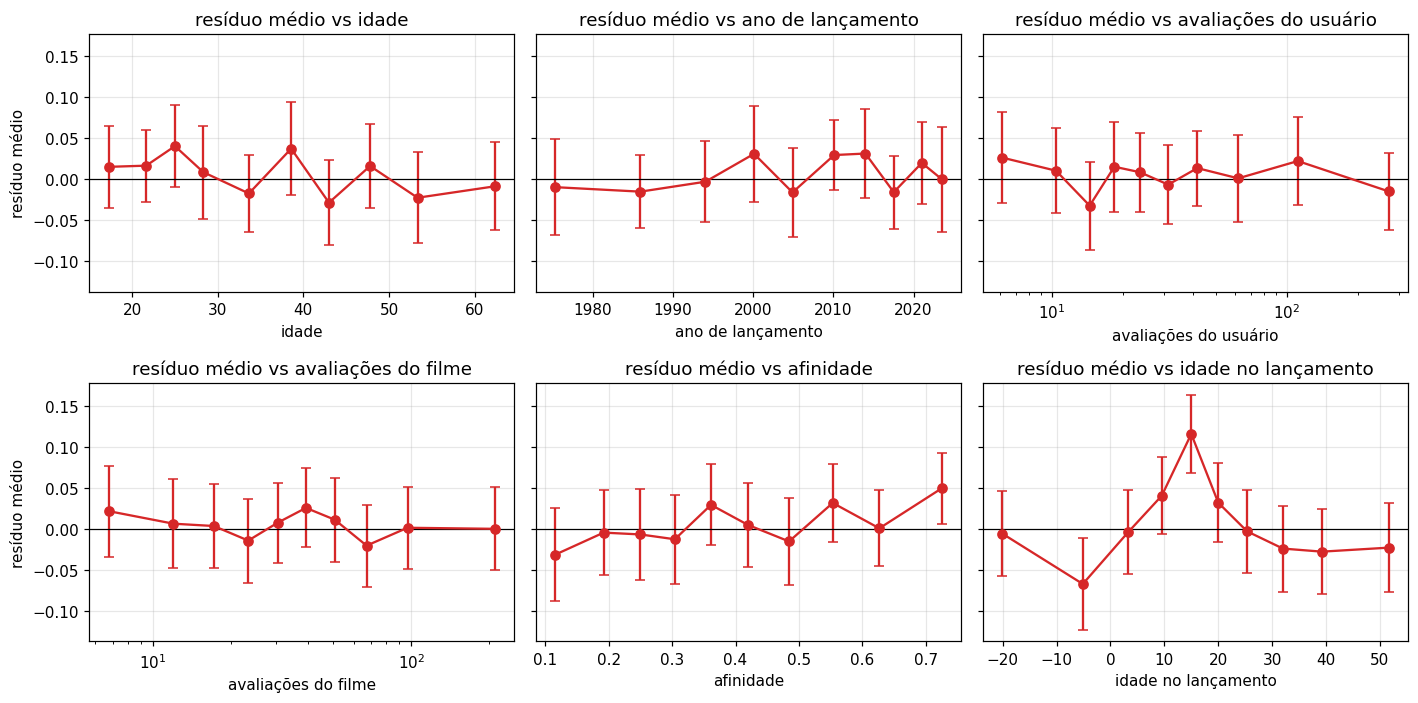

Resíduo médio por faixa de idade no lançamento:


,faixa,pares,resíduo médio
0,"(-70, 0]",844,-0.031
1,"(0, 10]",630,0.001
2,"(10, 20]",791,0.091
3,"(20, 30]",701,-0.001
4,"(30, 90]",1034,-0.027


In [5]:
variables = [('age', 'idade'), ('release_year', 'ano de lançamento'),
             ('user_n_ratings', 'avaliações do usuário'), ('movie_n_ratings', 'avaliações do filme'),
             ('affinity', 'afinidade'), ('age_at_release', 'idade no lançamento')]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (column, label) in zip(axes.ravel(), variables):
    table = binned(df[column], 10)
    ax.errorbar(table['x'], table['residuo'], yerr=2 * table['ep'], fmt='o-', capsize=3, color='C3')
    ax.axhline(0, color='k', lw=0.8)
    ax.set(xlabel=label, title=f'resíduo médio vs {label}')
    if column in ('user_n_ratings', 'movie_n_ratings'):
        ax.set_xscale('log')
axes[0, 0].set_ylabel('resíduo médio')
axes[1, 0].set_ylabel('resíduo médio')
plt.tight_layout()
plt.show()

print('Resíduo médio por faixa de idade no lançamento:')
display(tables['idade no lançamento'][['faixa', 'pares', 'resíduo médio']].round(3))

**Leitura**
- **Idade, ano, contagens e afinidade não mostram padrões fortes.** A maioria das faixas tem resíduo médio dentro de ±2 erros padrão de zero. Os padrões que motivaram os experimentos anteriores, como o arco por ano e a curvatura da afinidade, foram absorvidos. A exceção mais visível é a faixa mais alta de afinidade, com uma leve subestimação (cerca de +0,05), no limite de dois erros padrão.
- **Resta um padrão na idade no lançamento.** Na faixa de 10 a 20 anos, o resíduo médio é de cerca de **+0,09**: o modelo ainda **subestima** as notas no pico da nostalgia, enquanto as faixas vizinhas ficam levemente negativas. O modelo captura a existência do pico, mas não toda a sua altura. Uma explicação provável é que o boosting avança em passos pequenos (taxa de aprendizado 0,05, com 200 árvores) e tem um mínimo de observações por folha, o que suaviza mudanças bruscas. Testar outras formas de representar o pico seria uma nova exploração, com o otimismo de seleção que isso traz, e por isso fica registrado como limitação.

## 4. Notas extremas: 0 e 5 estrelas

Aqui agrupamos os pares pela **nota real** e comparamos com a previsão média.

,pares,previsao_media,residuo_medio,RMSE
stars,,,,
0,30,1.092,-1.092,1.154
1,180,1.608,-0.608,0.741
2,633,2.293,-0.293,0.561
3,1106,3.075,-0.075,0.504
4,1184,3.899,0.101,0.466
5,867,4.645,0.355,0.483


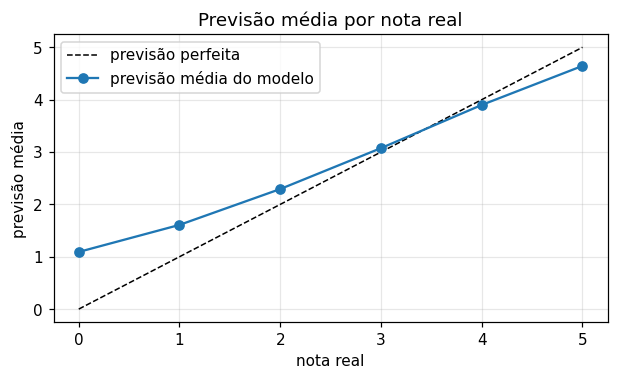

In [6]:
extremes = df.groupby('stars').agg(pares=('residuo', 'size'), previsao_media=('previsao', 'mean'),
                                   residuo_medio=('residuo', 'mean'),
                                   RMSE=('erro_quadratico', lambda s: np.sqrt(s.mean())))
display(extremes.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(extremes.index, extremes.index, 'k--', lw=1, label='previsão perfeita')
ax.plot(extremes.index, extremes['previsao_media'], 'o-', label='previsão média do modelo')
ax.set(xlabel='nota real', ylabel='previsão média', title='Previsão média por nota real')
ax.legend()
plt.show()

**Leitura**
- **O modelo "puxa" as notas extremas para o meio.** Quem deu 0 estrelas recebe, em média, previsão de cerca de 1,1; quem deu 1, cerca de 1,6; quem deu 5, cerca de 4,6. Os maiores erros estão nas notas 0 (RMSE 1,15) e 1 (0,74), que são raras: 30 e 180 pares, menos de 6% do total.
- **Isso não é, por si só, um viés do modelo.** Ao minimizar o erro quadrático, o melhor que um modelo pode fazer é prever a **média condicional** da nota dado o que se sabe do par, $E[Y \mid x]$. Para dois pares com os mesmos atributos, um pode dar 0 e outro 3 por causas que os atributos não registram: é o ruído irredutível, que faz o oráculo ter RMSE 0,39. Quem deu 0 é, em geral, um par cuja nota caiu bem abaixo do esperado. Por isso, agrupar pela **nota real** sempre mostra esse padrão, mesmo num modelo perfeito. Para procurar viés, o teste certo é agrupar pela **previsão** (seção 2), e lá os desvios são pequenos.
- **Prever 0 ou 5 só seria vantajoso com certeza.** Arriscar notas extremas diante da incerteza aumentaria o erro quadrático médio. Por isso o enunciado pede previsões reais, e não a classe mais provável.

## 5. A distribuição dos resíduos

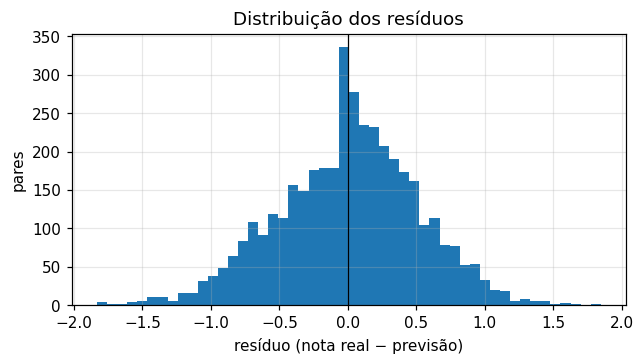

média = 0.0043 | desvio = 0.5128 | assimetria = -0.188 | curtose em excesso = 0.175


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(df['residuo'], bins=50, color='C0')
ax.axvline(0, color='k', lw=0.8)
ax.set(xlabel='resíduo (nota real − previsão)', ylabel='pares', title='Distribuição dos resíduos')
plt.show()
print(f"média = {df['residuo'].mean():.4f} | desvio = {df['residuo'].std():.4f} | "
      f"assimetria = {df['residuo'].skew():.3f} | curtose em excesso = {df['residuo'].kurt():.3f}")

**Leitura:** os resíduos estão centrados em zero e têm forma próxima de simétrica, com uma cauda um pouco mais longa à esquerda: são os poucos pares com notas muito abaixo do esperado, como as notas 0 e 1 da seção 4. Não há erros extremos isolados que dominem o RMSE.

## 6. Conclusões

| Pergunta | Resposta |
|---|---|
| O desempenho muda muito entre regiões? | Varia de cerca de 0,46 a 0,59, sem grupos com desempenho ruim. Os maiores erros estão em usuários e filmes com poucas avaliações, em filmes mal avaliados e em afinidade baixa. |
| Há viés sistemático? | Pequeno. O resíduo médio fica perto de zero em quase todas as faixas, e o modelo está bem calibrado entre 1,5 e 4,0. Nos extremos, as previsões são levemente conservadoras. |
| Sobra padrão não capturado? | Sim, um: o pico da nostalgia ainda é subestimado em cerca de 0,09 estrela na faixa de 10 a 20 anos. |
| E as notas extremas? | São puxadas para o meio (0 → 1,1; 5 → 4,6). É o comportamento esperado de quem minimiza o erro quadrático diante do ruído irredutível, não um defeito específico do modelo. |

**Em termos do curso.** O RMSE agregado de 0,52 está entre a regressão de referência (0,82) e o piso do oráculo (0,39). O diagnóstico mostra que o erro restante é, em boa parte, **ruído**: ele se concentra onde a informação é mais fraca (médias com poucas notas) e nas notas raras e extremas, que nenhum atributo antecipa. A parte de **viés** que sobra é pequena e localizada, no pico da nostalgia.

## Registro reproduzível desta execução

In [8]:
from src.current_results import save_run
save_run(ROOT, '12_diagnostico_modelo_final', df, y, {MODEL_NAME: predictions}, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP)

Resultados verificados e salvos em results/rodada_atual/12_diagnostico_modelo_final.json
